# Black Marble Nighttime Lights over Bangalore - 21 Nov 2026

This notebook downloads the NASA Black Marble **VJ146A2_NRT** daily nighttime lights tile
(NOAA-20 VIIRS, gap-filled, lunar BRDF-corrected, ~500 m) for **21 Nov 2026**.

- Tile: `h25v07` (10 x 10 degree tile covering 70-80 E, 10-20 N)
- Requires a free NASA Earthdata login: https://urs.earthdata.nasa.gov
- Near real-time (NRT) files are only kept online for about 7 days. If the NRT file is gone,
  the notebook falls back to the standard **VJ146A2** product.

## How this data was found: NASA Earthdata MCP

The dataset for this notebook was found using **Claude Code** with the
**NASA Earthdata MCP server**, which gives Claude tools to search NASA's
Common Metadata Repository (CMR) directly. This avoids guessing dataset names or dates:
every product and file listed below was checked to actually exist.

### Prompts used

1. *"What is the latest NASA Blackmarble image available over Bangalore, India?"*
2. *"Write the notebook to fetch, process and download the latest tile."*

### MCP tools and how they were used

The MCP server provides tools for finding datasets (`get_collections`) and for
checking that actual files exist for a place and time (`get_granules`).

### From Search to Code

The MCP server is only used for finding the data. The notebook below uses the
`earthaccess` Python package to repeat the same search in code, log in and download
the file, so it can be re-run without Claude.

## Setup

Detect the runtime environment and install the required packages if running on Colab.

In [ ]:
%%capture
import os

if 'COLAB_RELEASE_TAG' in os.environ:
    !pip install earthaccess rioxarray h5netcdf

In [ ]:
import os

IN_COLAB = 'COLAB_RELEASE_TAG' in os.environ

data_folder = 'data'
output_folder = 'output'

if not os.path.exists(data_folder):
    os.mkdir(data_folder)
if not os.path.exists(output_folder):
    os.mkdir(output_folder)

In [ ]:
import earthaccess
import numpy as np
import pandas as pd
import xarray as xr
import rioxarray  # noqa: F401  (adds the .rio accessor to xarray)
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

## Settings

In [2]:
date = '2026-11-21'

# Bangalore city centre (lon, lat) and a bounding box around the metro area
bangalore_point = (77.59, 12.97)
bbox = {'minx': 77.35, 'miny': 12.75, 'maxx': 77.85, 'maxy': 13.20}

# Black Marble tile h25v07: each tile is 10 x 10 degrees, 2400 x 2400 pixels
tile_west = 70.0
tile_north = 20.0
tile_size_deg = 10.0
tile_pixels = 2400

## Log in to NASA Earthdata

You need a free [Earthdata Login](https://urs.earthdata.nasa.gov) account.

- **Colab**: you will be prompted to enter your username and password.
- **Local**: credentials are read from a netrc file: `C:\Users\<you>\_netrc` on Windows
(`~/.netrc` on Mac/Linux). Create it once in a text editor with this single line:

```
machine urs.earthdata.nasa.gov login YOUR_USERNAME password YOUR_PASSWORD
```

Locally, `strategy='netrc'` makes the cell fail immediately with a clear error if the file
is missing, instead of waiting for a typed password prompt that some notebook editors hide.

In [3]:
strategy = 'interactive' if IN_COLAB else 'netrc'
auth = earthaccess.login(strategy=strategy)
print('Logged in:', auth.authenticated)

Logged in: True


## Search for the tile

In [4]:
# File names contain the date as AYYYYDDD (year + day of year), e.g. A2026325
doy_tag = 'A' + pd.Timestamp(date).strftime('%Y%j')

def find_tile(short_name):
    found = earthaccess.search_data(
        short_name=short_name,
        temporal=(date, date),
        point=bangalore_point,
    )
    # The search can also return the previous day's tile (it ends at midnight,
    # which overlaps our window), so keep only files for our date.
    return [r for r in found if doy_tag in r.data_links()[0]]

results = find_tile('VJ146A2_NRT')
if len(results) == 0:
    print('NRT file not found (older than ~7 days?). Trying the standard VJ146A2 product.')
    results = find_tile('VJ146A2')

print(f'Found {len(results)} file(s) for {doy_tag}')
for r in results:
    print(r.data_links())

Found 1 file(s) for A2026325
['https://nrt3.modaps.eosdis.nasa.gov/api/v2/content/archives/allData/5200/VJ146A2_NRT/2026/325/VJ146A2_NRT.A2026325.h25v07.002.2026326061317.h5']


## Download

In [ ]:
files = earthaccess.download(results, local_path=data_folder)
h5_file = files[0]
print(h5_file)

## Open the HDF5 file

Black Marble files are HDF-EOS5. The data lives in the group
`HDFEOS/GRIDS/VIIRS_Grid_DNB_2d/Data Fields`. The arrays have no named dimensions,
so `phony_dims='sort'` tells h5netcdf to make up names for them.

In [ ]:
group = 'HDFEOS/GRIDS/VIIRS_Grid_DNB_2d/Data Fields'
ds = xr.open_dataset(h5_file, engine='h5netcdf', group=group, phony_dims='sort')
ds

In [ ]:
ntl_name = 'Gap_Filled_DNB_BRDF-Corrected_NTL'
ntl = ds[ntl_name]
print(ntl.dims, ntl.shape)
print(ntl.attrs)

## Add coordinates

Rather than relying on coordinate arrays inside the file, compute pixel-centre
longitudes and latitudes from the tile position. Each pixel is 15 arc-seconds (10 / 2400 degrees).

In [8]:
pixel_size = tile_size_deg / tile_pixels
lons = tile_west + (np.arange(tile_pixels) + 0.5) * pixel_size
lats = tile_north - (np.arange(tile_pixels) + 0.5) * pixel_size

y_dim, x_dim = ntl.dims
ntl = ntl.rename({y_dim: 'y', x_dim: 'x'})
ntl = ntl.assign_coords(x=lons, y=lats)
ntl = ntl.rio.set_spatial_dims(x_dim='x', y_dim='y').rio.write_crs('EPSG:4326')

# Units after scaling are nW/cm2/sr. xarray already applied scale_factor and _FillValue.
print('min:', float(ntl.min()), 'max:', float(ntl.max()))

min: 0.0 max: 4863.58935546875


## Full tile overview

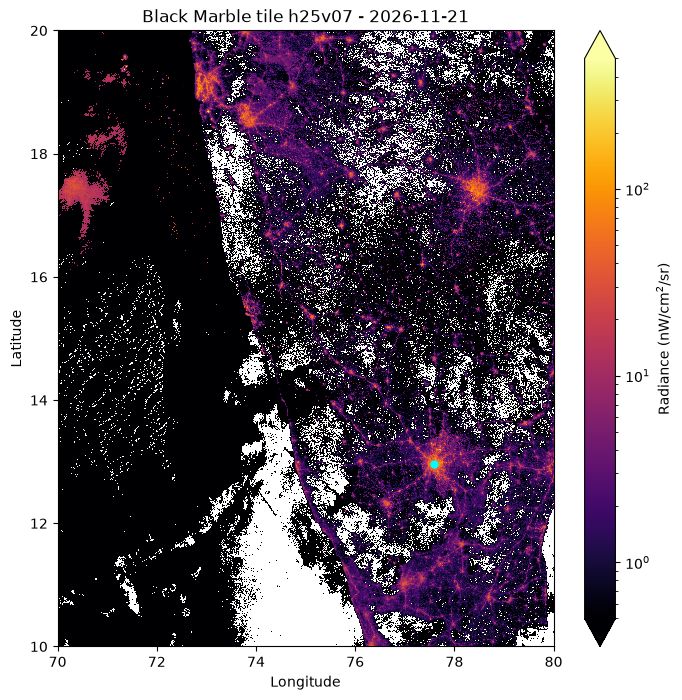

In [9]:
fig, ax = plt.subplots(figsize=(8, 8))
ntl.where(ntl > 0).plot.imshow(
    ax=ax, cmap='inferno', norm=LogNorm(vmin=0.5, vmax=500),
    cbar_kwargs={'label': 'Radiance (nW/cm$^2$/sr)'},
)
ax.plot(*bangalore_point, marker='o', color='cyan', markersize=5)
ax.set_title(f'Black Marble tile h25v07 - {date}')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.show()

## Clip to Bangalore and plot

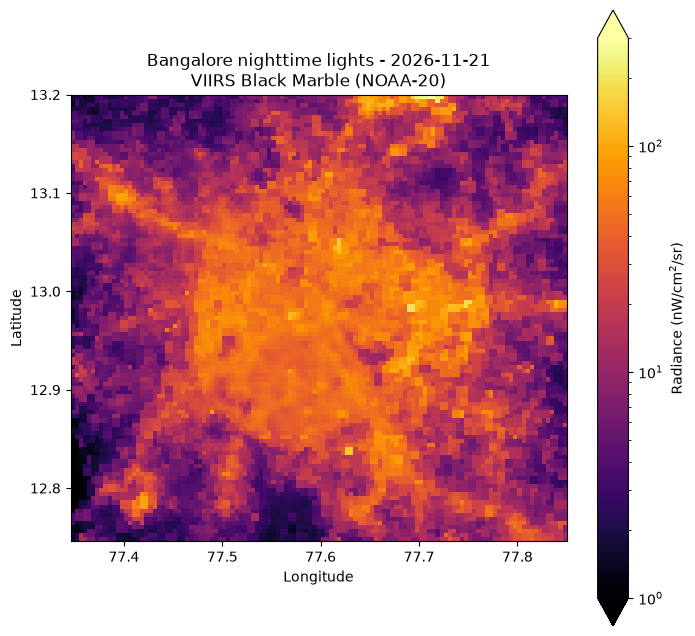

In [10]:
ntl_blr = ntl.rio.clip_box(**bbox)

fig, ax = plt.subplots(figsize=(8, 8))
ntl_blr.where(ntl_blr > 0).plot.imshow(
    ax=ax, cmap='inferno', norm=LogNorm(vmin=1, vmax=300),
    cbar_kwargs={'label': 'Radiance (nW/cm$^2$/sr)'},
)
ax.set_title(f'Bangalore nighttime lights - {date}\nVIIRS Black Marble (NOAA-20)')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_aspect('equal')
plt.show()

## Save the clipped image as GeoTIFF

In [ ]:
out_tif = os.path.join(output_folder, f'bangalore_ntl_{date}.tif')
ntl_blr.rio.to_raster(out_tif)
print('Saved', out_tif)